# Case Study: Vacation Accommodation Analysis

**Student Name:** Jean Yves Nkwane Ebongue  
**Student ID:** 77201393552

---

**"Where Should We Stay?" – Data-Driven Travel Decisions**

You are a junior data analyst at a travel platform.

Your team wants to better understand how different types of accommodation perform and what factors influence customer experience, pricing, and demand.

You are given a dataset containing:

* Airbnb listings
* Hotel listings
* Location characteristics
* Ratings, engagement, and booking-related data

Your task is to define, refine, and answer meaningful analytical questions using the dataset `vacation_accommodations.csv`.

**Project Aim:** My goal here is to dig into this accommodation dataset and figure out what drives prices, whether there are hidden groups of listings, and if it is possible to predict which places get good reviews. I plan to use regression, clustering, and classification for that.

### Assumptions

Before I start, a few things I'm assuming about the data since the task doesn't specify everything:

- The `date` column is when the listing data was collected, not a booking date.
- `rating` is on a 1 to 5 scale.
- `distance_to_center` is in kilometers.
- Each row represents one unique listing.

## 1. Project Objective & Definition
Below is a list of potential analytical questions.

1. Do accommodations with more amenities perform better?
2. What factors influence accommodation price?
3. Which accommodation is the best?
4. Are hotels better than Airbnbs?
5. Can we predict whether a listing will be highly rated?
6. What is the average price of accommodations?
7. What factors are associated with high customer ratings?
8. Are there distinct types of accommodations based on features and location?
9. Do more expensive accommodations have better ratings?
10. What factors drive booking likelihood or demand?
11. Which features are most important for customer satisfaction?
12. How does location impact price and ratings?


**Task:**
* For each question, provide a brief evaluation explaining whether the question is well-defined and the reason behind your evaluation.
* Select two (2) questions that you consider meaningful and feasible.
* Refine or rephrase your selected questions to make them precise and analytically sound, if needed.
* Ensure your selected questions reflect different analytical perspectives (e.g., prediction, comparison, segmentation).
* Briefly justify your choices.

---

### Optional Bonus (max. 4 points)
You may choose to analyze **one (1) additional question** for bonus points.

To be eligible for bonus:

* The question must reflect a different analytical perspective or method
* The analysis must provide clear additional value, not repetition

### Part 1: Brief Evaluation of all 12 Questions

1. **Amenities → performance?** Not feasible — no amenity data in the dataset, and "perform better" is too vague.
2. **Factors → price?** Good one. `price_per_night` is a clear target with plenty of predictors available. Works for regression.
3. **Best accommodation?** Too vague. "Best" could mean cheapest, cleanest, best rated...
4. **Hotels vs Airbnbs?** Also vague. "Better" is subjective without a defined metric.
5. **Predict high rating?** Feasible with a threshold like >= 4.0. Nice classification problem.
6. **Average price?** One line of code. Not enough for a full analysis section.
7. **Factors → high ratings?** Overlaps too much with Q5.
8. **Distinct accommodation types?** Interesting — basically asking for clustering. Different analytical lens.
9. **Expensive = better rated?** Too narrow. Just a scatter plot or correlation.
10. **Booking demand?** No booking data available, would need shaky proxies.
11. **Customer satisfaction features?** Too similar to Q5 and Q7.
12. **Location → price & ratings?** Better as a sub-question within Q2.

---

### Part 2: My Selected Questions

I picked questions that each need a different method:

* **Q1 (from Q2, refined):** *"What factors influence accommodation price per night, and can I build a regression model to predict it?"*
* **Q2 (from Q8, refined):** *"Are there distinct segments of vacation accommodations based on their features, and what characterizes each segment?"*
* **Bonus (from Q5, refined):** *"Can I predict whether a listing will receive a high rating (>= 4.0) based on its characteristics?"*

---

### Part 3: Why these three?

1. **Q1 → Regression.** Price prediction is directly useful for a travel platform. Linear regression shows exactly which features push prices up or down.
2. **Q2 → Clustering.** I want to see if there are hidden groups beyond just Airbnb vs Hotel. K-Means can find patterns across multiple features at once.
3. **Bonus → Classification.** Predicting good vs bad ratings is actionable. I'll use logistic regression with a 4.0 threshold.

## 2. Python Libraries Imports

**Task:** Import all necessary Python libraries in **one single** cell. Comment to explain shortly what you use each library for.

In [1]:
# Putting all my imports in one cell as requested

import pandas as pd                # For loading and cleaning the data
import numpy as np                 # For calculating RMSE and other math

import matplotlib.pyplot as plt    # Base library for all my plots
import seaborn as sns              # To make the plots look much better

# Scikit-learn stuff for my three models
from sklearn.model_selection import train_test_split   # To split into train and test sets
from sklearn.preprocessing import StandardScaler       # Needed to scale data before K-Means
from sklearn.preprocessing import LabelEncoder         # For categorical data (though I used get_dummies mostly)
from sklearn.linear_model import LinearRegression      # For Q1: predicting the price
from sklearn.linear_model import LogisticRegression    # For Bonus: predicting high ratings
from sklearn.cluster import KMeans                     # For Q2: finding customer segments

# The metrics I need to evaluate my models
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore') # Hiding warnings so the notebook stays clean

# Setting up default styles for my charts so I don't have to repeat it
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print("Libraries imported!")

Libraries imported!


## 3. Exploratory Data Analysis (EDA) & Data Cleaning

**Task:** Load the dataset. Explore the dataset and identify any data quality issues. Note down the issue and how to fix them. Implement the fix.
You may use multiple cells if needed.

In [2]:
# Let's load the data first
df = pd.read_csv('vacation_accommodations.csv')

print(f"Dataset has {df.shape[0]} rows and {df.shape[1]} columns.")
print()
df.head()

Dataset has 1236 rows and 14 columns.



,id,accommodation_type,location_type,room_type,capacity,distance_to_center,price_per_night,cleanliness_score,service_score,rating,num_reviews,likes,comments,date
0,622,Airbnb,city_center,entire_home,5,5.05,166.47,4.83,3.72,3.53,64,154,26,2023-06-10
1,955,Airbnb,city_center,entire_home,3,6.93,137.48,3.39,3.40,2.31,38,123,11,2023-08-13
2,1174,Airbnb,city_center,shared_room,2,12.50,118.96,4.38,3.11,4.26,77,188,21,2023-08-01
3,124,Airbnb,city_center,entire_home,4,5.23,117.56,3.87,4.52,4.08,71,169,24,2023-02-19
4,712,Airbnb,secluded,entire_home,3,14.82,96.06,3.90,3.42,4.05,70,228,28,2023-02-09


In [3]:
# I want to see the column types and if there are obvious missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1236 entries, 0 to 1235
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  1236 non-null   int64  
 1   accommodation_type  1236 non-null   str    
 2   location_type       1236 non-null   str    
 3   room_type           1236 non-null   str    
 4   capacity            1236 non-null   int64  
 5   distance_to_center  1236 non-null   float64
 6   price_per_night     1176 non-null   float64
 7   cleanliness_score   1174 non-null   float64
 8   service_score       1236 non-null   float64
 9   rating              1174 non-null   float64
 10  num_reviews         1236 non-null   int64  
 11  likes               1236 non-null   int64  
 12  comments            1236 non-null   int64  
 13  date                1236 non-null   str    
dtypes: float64(5), int64(5), str(4)
memory usage: 135.3 KB


In [4]:
# Getting a statistical summary to easily spot weird numbers like negatives or crazy max values
df.describe()

,id,capacity,distance_to_center,price_per_night,cleanliness_score,service_score,rating,num_reviews,likes,comments
count,1236.000000,1236.000000,1236.000000,1176.000000,1174.000000,1236.000000,1174.000000,1236.000000,1236.000000,1236.000000
mean,601.799353,3.044498,7.405574,151.527143,3.936763,3.987638,4.180324,61.368932,206.586570,18.132686
std,346.838319,1.403452,4.418631,92.370815,0.677505,0.590974,0.594941,9.852917,35.719847,6.008377
min,1.000000,1.000000,-3.000000,20.420000,1.660000,2.070000,2.220000,33.000000,89.000000,-2.000000
25%,301.750000,2.000000,3.725000,113.072500,3.460000,3.580000,3.750000,55.000000,181.000000,14.000000
50%,601.500000,3.000000,7.240000,141.945000,3.970000,3.990000,4.180000,61.000000,208.000000,18.000000
75%,902.000000,4.000000,11.252500,172.072500,4.460000,4.420000,4.650000,68.000000,233.000000,22.000000
max,1200.000000,5.000000,14.980000,1219.850000,5.000000,5.000000,6.000000,91.000000,308.000000,36.000000


In [5]:
# Time to systematically check for data quality issues we discussed in class

print("=" * 60)
print("MY DATA QUALITY CHECK")
print("=" * 60)

# Check for missing values first
print("\n--- Missing Values ---")
missing = df.isnull().sum()
print(missing[missing > 0])
print(f"Total NaNs: {df.isnull().sum().sum()}")

# Check for duplicates
print("\n--- Duplicates ---")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate IDs: {df['id'].duplicated().sum()}")

# Check for typos in text columns
print("\n--- Categories ---")
# I spotted 'citycentre' vs 'city_center' here
print(f"location_type values: {df['location_type'].unique().tolist()}")

# Logic checks: values that don't make sense in reality
print("\n--- Invalid Values ---")
print(f"Negative distances: {(df['distance_to_center'] < 0).sum()}")
print(f"Negative comments: {(df['comments'] < 0).sum()}")
print(f"Rating above 5.0: {(df['rating'] > 5.0).sum()}")

# Finding outliers using the 1.5 * IQR rule we learned
print("\n--- Outliers (IQR Method) ---")
for col in ['price_per_night', 'capacity', 'distance_to_center',
            'cleanliness_score', 'service_score', 'rating', 'num_reviews']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Counting how many rows are outside the normal bounds
    n_out = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    if n_out > 0:
        print(f"  {col}: {n_out} outliers found")

MY DATA QUALITY CHECK

--- Missing Values ---
price_per_night      60
cleanliness_score    62
rating               62
dtype: int64
Total NaNs: 184

--- Duplicates ---
Duplicate rows: 36
Duplicate IDs: 36

--- Categories ---
location_type values: ['city_center', 'secluded', 'suburb', 'citycentre']

--- Invalid Values ---
Negative distances: 13
Negative comments: 2
Rating above 5.0: 12

--- Outliers (IQR Method) ---
  price_per_night: 27 outliers found
  cleanliness_score: 3 outliers found
  service_score: 4 outliers found
  rating: 3 outliers found
  num_reviews: 7 outliers found


**Issues I found:**

| # | Problem | Where | Count | Severity |
|---|---------|-------|-------|----------|
| 1 | Missing values | `price_per_night`, `cleanliness_score`, `rating` | ~180 total | Medium |
| 2 | Duplicate rows | Whole dataset | 36 rows | High |
| 3 | Typo | `location_type`: "citycentre" vs "city_center" | 25 rows | Medium |
| 4 | Negative distance | `distance_to_center` | A few rows | Medium |
| 5 | Negative comments | `comments` | 2 rows | Low |
| 6 | Rating out of range | `rating` goes above 5.0 | Some rows | Medium |
| 7 | Price outliers | `price_per_night` has extreme values | ~27 rows | Medium |

Let me fix all of these below.

In [6]:
print(f"Rows before cleaning: {df.shape[0]}")

# 1. Dropping duplicates so they don't skew my averages
df = df.drop_duplicates()
print(f"Rows after removing duplicates: {df.shape[0]}")

# 2. Fixing the typo so my model doesn't think they are two different places
df['location_type'] = df['location_type'].replace('citycentre', 'city_center')

# 3. Distance can't be negative, I assume it's a typo so I'll take the absolute value
df['distance_to_center'] = df['distance_to_center'].abs()

# 4. Comments can't be less than 0, setting them to 0
df.loc[df['comments'] < 0, 'comments'] = 0

# 5. Rating scale is 1-5, so I'll cap the few that are above 5
df.loc[df['rating'] > 5.0, 'rating'] = 5.0

# 6. I'm filling missing values with the median instead of the mean. 
#    This is more robust against price outliers as we discussed in the imputation lecture.
df['price_per_night'] = df['price_per_night'].fillna(df['price_per_night'].median())
df['cleanliness_score'] = df['cleanliness_score'].fillna(df['cleanliness_score'].median())
df['rating'] = df['rating'].fillna(df['rating'].median())

# 7. For the extreme prices, I'll cap them using the IQR bounds instead of deleting the rows.
#    I want to keep the rest of the data in those rows.
Q1_p = df['price_per_night'].quantile(0.25)
Q3_p = df['price_per_night'].quantile(0.75)
IQR_p = Q3_p - Q1_p
df['price_per_night'] = df['price_per_night'].clip(lower=Q1_p - 1.5*IQR_p, upper=Q3_p + 1.5*IQR_p)

# 8. Converting date to datetime so I can extract the month later if needed
df['date'] = pd.to_datetime(df['date'])

print(f"Cleaning done! Final shape: {df.shape}")
print(f"Missing values left: {df.isnull().sum().sum()}")

Rows before cleaning: 1236
Rows after removing duplicates: 1200
Cleaning done! Final shape: (1200, 14)
Missing values left: 0


In [7]:
# Quick sanity check to make sure the cleaning worked
print(df.describe().to_string())
print()
print(f"NaNs: {df.isnull().sum().sum()}, Duplicates: {df.duplicated().sum()}")
df.head()

                id     capacity  distance_to_center  price_per_night  cleanliness_score  service_score       rating  num_reviews        likes     comments                 date
count  1200.000000  1200.000000         1200.000000      1200.000000        1200.000000    1200.000000  1200.000000  1200.000000  1200.000000  1200.000000                 1200
mean    600.500000     3.041667            7.506667       142.599721           3.943092       3.986183     4.168508    61.350833   206.542500    18.161667  2023-07-01 14:44:24
min       1.000000     1.000000            0.100000        29.761250           1.660000       2.070000     2.220000    33.000000    89.000000     0.000000  2023-01-01 00:00:00
25%     300.750000     2.000000            3.747500       114.207500           3.500000       3.580000     3.787500    55.000000   181.000000    14.000000  2023-04-01 18:00:00
50%     600.500000     3.000000            7.305000       141.825000           3.970000       3.990000     4.180000    6

NaNs: 0, Duplicates: 0


,id,accommodation_type,location_type,room_type,capacity,distance_to_center,price_per_night,cleanliness_score,service_score,rating,num_reviews,likes,comments,date
0,622,Airbnb,city_center,entire_home,5,5.05,166.47,4.83,3.72,3.53,64,154,26,2023-06-10
1,955,Airbnb,city_center,entire_home,3,6.93,137.48,3.39,3.40,2.31,38,123,11,2023-08-13
2,1174,Airbnb,city_center,shared_room,2,12.50,118.96,4.38,3.11,4.26,77,188,21,2023-08-01
3,124,Airbnb,city_center,entire_home,4,5.23,117.56,3.87,4.52,4.08,71,169,24,2023-02-19
4,712,Airbnb,secluded,entire_home,3,14.82,96.06,3.90,3.42,4.05,70,228,28,2023-02-09


**Why I made these choices:**

- **Duplicates removed:** they would inflate counts and skew averages.
- **Typo fix:** if I left "citycentre" as-is, the model would treat it as a separate location, which is wrong.
- **Negative values corrected:** distance and comment count can't be negative in reality.
- **Ratings capped at 5:** anything above the scale max is clearly an error.
- **Median for NaNs:** I went with median over mean because mean gets dragged by the extreme prices. We talked about this tradeoff in the imputation lecture.
- **Price capping instead of deleting:** I didn't want to lose the other good data (ratings, location, etc.) in those rows. Capping with `.clip()` limits the extreme values while keeping the rows.

## 4. Data Transformation

**Task:** Choose the variables that you will use and perform data transformation. Justify the choice of the variables, together with the transformation decisions. You may use multiple cells if needed.

In [8]:
# Making a copy so I don't break my cleaned dataframe
df_clean = df.copy()

# 1. Creating a new 'engagement_score' by adding likes and comments
#    They both measure how much users interact, so combining them makes sense and reduces noise
df_clean['engagement_score'] = df_clean['likes'] + df_clean['comments']

# 2. Extracting month from the date in case I want to look for seasonality
df_clean['month'] = df_clean['date'].dt.month

# 3. Creating a binary target for my Bonus question
#    I chose >= 4.0 as "high rating" because it splits the dataset fairly well
df_clean['high_rating'] = (df_clean['rating'] >= 4.0).astype(int)

print(f"New features added: engagement_score, month, high_rating")
print(f"My rating split is: {df_clean['high_rating'].value_counts().to_dict()}")
print(f"(About {df_clean['high_rating'].mean()*100:.1f}% are considered highly rated)")

New features added: engagement_score, month, high_rating
My rating split is: {1: 769, 0: 431}
(About 64.1% are considered highly rated)


In [9]:
# ML models need numbers, so I have to encode the text columns (like Hotel vs Airbnb)
# I'm using get_dummies (One-Hot Encoding) with drop_first=True to avoid multicollinearity
# If it's not a Hotel, I know it's an Airbnb, so one column is enough
df_encoded = pd.get_dummies(
    df_clean,
    columns=['accommodation_type', 'location_type', 'room_type'],
    drop_first=True,
    dtype=int
)

print(f"Shape after encoding: {df_encoded.shape}")
print(f"New dummy columns created: {[c for c in df_encoded.columns if c not in df_clean.columns]}")

Shape after encoding: (1200, 19)
New dummy columns created: ['accommodation_type_Hotel', 'location_type_secluded', 'location_type_suburb', 'room_type_private_room', 'room_type_shared_room']


In [10]:
# I need to scale my data for K-Means clustering.
# K-Means calculates distances, so if I don't scale, price (range 20-260) 
# will completely dominate rating (range 2-5) just because the numbers are bigger.

cluster_features = ['price_per_night', 'distance_to_center', 'capacity',
                    'cleanliness_score', 'service_score', 'rating',
                    'num_reviews', 'engagement_score']

scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_encoded[cluster_features]),
    columns=cluster_features,
    index=df_encoded.index
)

# Checking if the scaling worked (mean should be ~0, std should be ~1)
print("Scaled data check:")
print(df_scaled.describe().round(2).to_string())

Scaled data check:


       price_per_night  distance_to_center  capacity  cleanliness_score  service_score   rating  num_reviews  engagement_score
count          1200.00             1200.00   1200.00            1200.00        1200.00  1200.00      1200.00           1200.00
mean             -0.00               -0.00      0.00               0.00          -0.00    -0.00        -0.00             -0.00
std               1.00                1.00      1.00               1.00           1.00     1.00         1.00              1.00
min              -2.58               -1.72     -1.45              -3.46          -3.24    -3.50        -2.87             -3.18
25%              -0.65               -0.87     -0.74              -0.67          -0.69    -0.69        -0.64             -0.76
50%              -0.02               -0.05     -0.03               0.04           0.01     0.02        -0.04              0.01
75%               0.64                0.88      0.68               0.75           0.73     0.81         0.67  

**Transformation decisions:**

- **`engagement_score`:** likes and comments both measure interaction, so I combined them to reduce redundancy.
- **One-Hot Encoding:** ML models need numbers, not text. I chose one-hot over label encoding because label encoding would imply an order between categories (e.g., suburb > city_center) which makes no sense.
- **`drop_first=True`:** avoids multicollinearity — if something is not a Hotel, it must be an Airbnb.
- **StandardScaler:** K-Means uses distances, so features need to be on the same scale. Otherwise price would dominate everything.

## 5. Data Visualization & Pattern Recognition

**Task:** Generate any relevant visualizations and justify the choice of the graphs. Check for patterns and relationships between variables that can support your answer for the question. You may use multiple cells if needed.

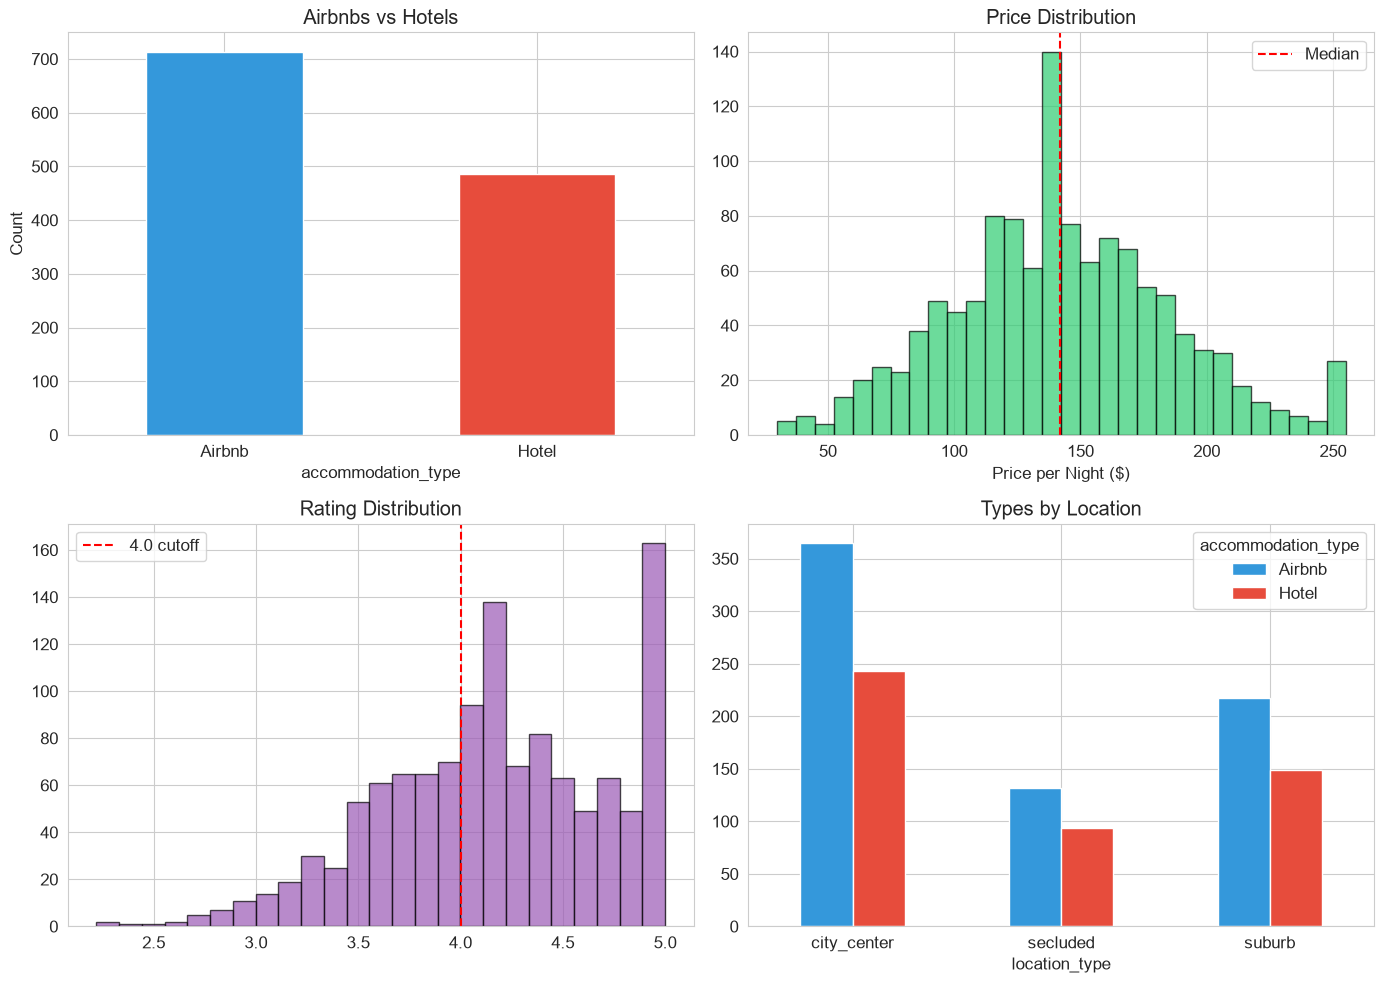

In [11]:
# I'll create some general charts to understand the overall shape of the data
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar chart for category counts (Airbnb vs Hotel)
ax1 = axes[0, 0]
df_clean['accommodation_type'].value_counts().plot(kind='bar', ax=ax1, color=['#3498db', '#e74c3c'])
ax1.set_title('Airbnbs vs Hotels')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=0)

# 2. Histogram to see how prices are distributed
ax2 = axes[0, 1]
ax2.hist(df_clean['price_per_night'], bins=30, color='#2ecc71', edgecolor='black', alpha=0.7)
ax2.set_title('Price Distribution')
ax2.set_xlabel('Price per Night ($)')
ax2.axvline(df_clean['price_per_night'].median(), color='red', linestyle='--', label='Median')
ax2.legend()

# 3. Histogram for ratings, checking where my 4.0 cutoff falls
ax3 = axes[1, 0]
ax3.hist(df_clean['rating'], bins=25, color='#9b59b6', edgecolor='black', alpha=0.7)
ax3.set_title('Rating Distribution')
ax3.axvline(4.0, color='red', linestyle='--', label='4.0 cutoff')
ax3.legend()

# 4. Bar chart crossing location and type
ax4 = axes[1, 1]
pd.crosstab(df_clean['location_type'], df_clean['accommodation_type']).plot(kind='bar', ax=ax4, color=['#3498db', '#e74c3c'])
ax4.set_title('Types by Location')
ax4.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

**Observations:**
- More Airbnbs than Hotels in the data, which makes sense.
- Prices look roughly normal after capping, median around $142.
- The 4.0 cutoff splits ratings fairly evenly — good for classification (no big class imbalance).
- City center has the most listings for both types.

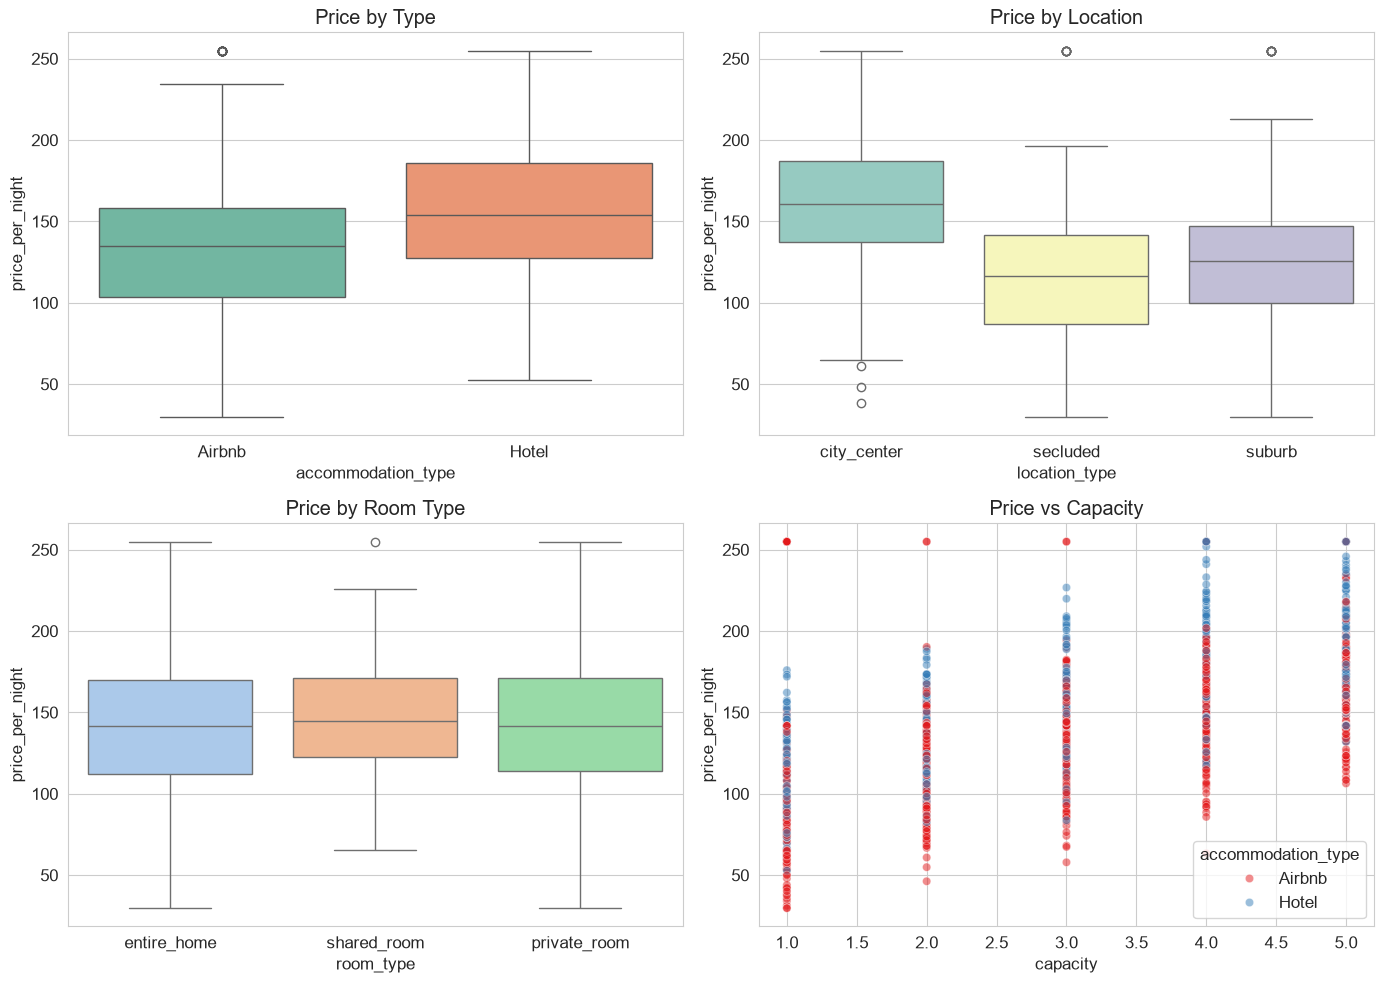

In [12]:
# For Question 1 (predicting price), I'll use boxplots to see how price changes across categories
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Does being a hotel make it more expensive?
sns.boxplot(data=df_clean, x='accommodation_type', y='price_per_night', ax=axes[0,0], palette='Set2')
axes[0,0].set_title('Price by Type')

# What about location?
sns.boxplot(data=df_clean, x='location_type', y='price_per_night', ax=axes[0,1], palette='Set3')
axes[0,1].set_title('Price by Location')

# Room type should definitely matter
sns.boxplot(data=df_clean, x='room_type', y='price_per_night', ax=axes[1,0], palette='pastel')
axes[1,0].set_title('Price by Room Type')

# I'll use a scatter plot for capacity since it's a number, not a category
sns.scatterplot(data=df_clean, x='capacity', y='price_per_night',
                hue='accommodation_type', ax=axes[1,1], alpha=0.5, palette='Set1')
axes[1,1].set_title('Price vs Capacity')

plt.tight_layout()
plt.show()

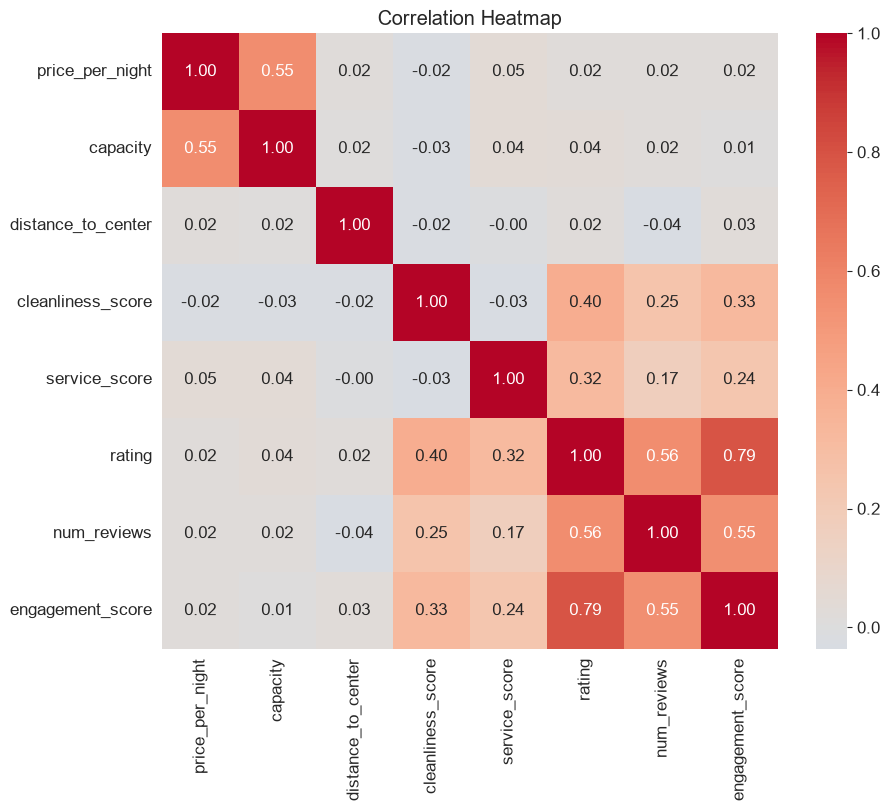


Features that correlate with price:
price_per_night       1.000000
capacity              0.554730
service_score         0.046506
num_reviews           0.023925
engagement_score      0.021730
rating                0.017950
distance_to_center    0.016207
cleanliness_score    -0.023990


In [13]:
# A heatmap is a great way to see which numerical variables are linked to each other
numerical_cols = ['price_per_night', 'capacity', 'distance_to_center',
                  'cleanliness_score', 'service_score', 'rating',
                  'num_reviews', 'engagement_score']

plt.figure(figsize=(10, 8))
corr = df_clean[numerical_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap')
plt.show()

# Let's print out just the correlations with price to make it easier to read
print("\nFeatures that correlate with price:")
print(corr['price_per_night'].sort_values(ascending=False).to_string())

**Q1 insights:**
- Capacity has the strongest link with price (~0.55). Bigger places = higher price, makes sense.
- Room type matters a lot — entire homes cost clearly more than shared rooms.
- Surprisingly, cleanliness and service barely affect price. Hosts with great quality aren't charging more for it.
- Location doesn't have as big an impact as I would have expected.

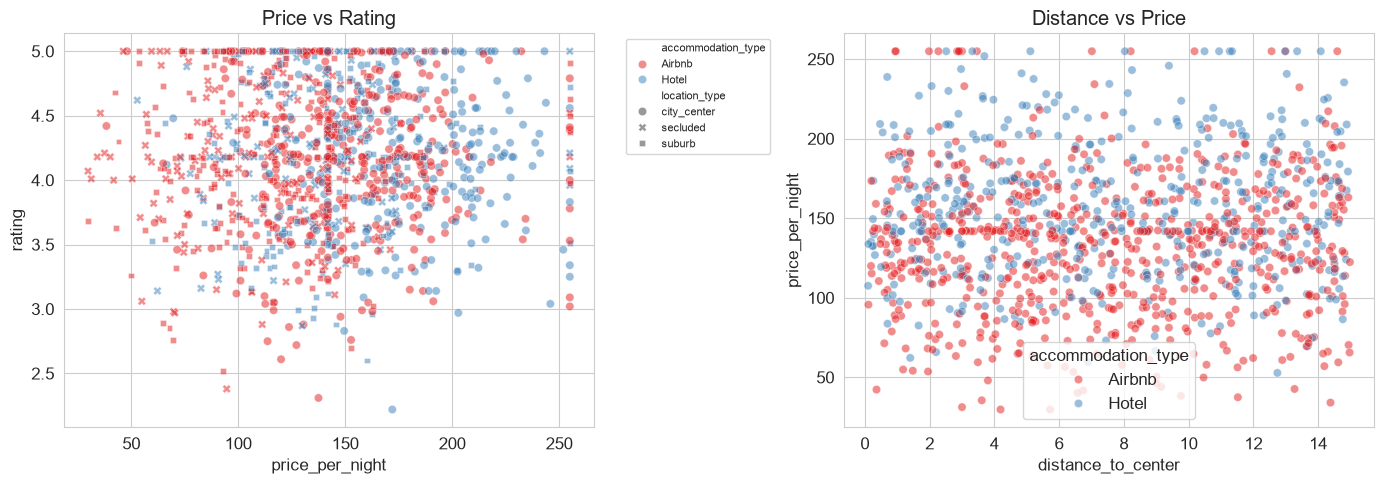

In [14]:
# For Question 2, I'll plot some scatters to see if I can spot any clusters by eye
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plotting price vs rating
sns.scatterplot(data=df_clean, x='price_per_night', y='rating',
                hue='accommodation_type', style='location_type',
                ax=axes[0], alpha=0.5, palette='Set1')
axes[0].set_title('Price vs Rating')
# Moving the legend out so it doesn't cover my points
axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

# Plotting distance vs price
sns.scatterplot(data=df_clean, x='distance_to_center', y='price_per_night',
                hue='accommodation_type', ax=axes[1], alpha=0.5, palette='Set1')
axes[1].set_title('Distance vs Price')

plt.tight_layout()
plt.show()

**Q2 observations:**
I can't really see obvious clusters just from these 2D plots — the data looks like one big cloud. That's exactly why I need K-Means: it can look at all 8 features at once and find patterns I can't see on a flat chart.

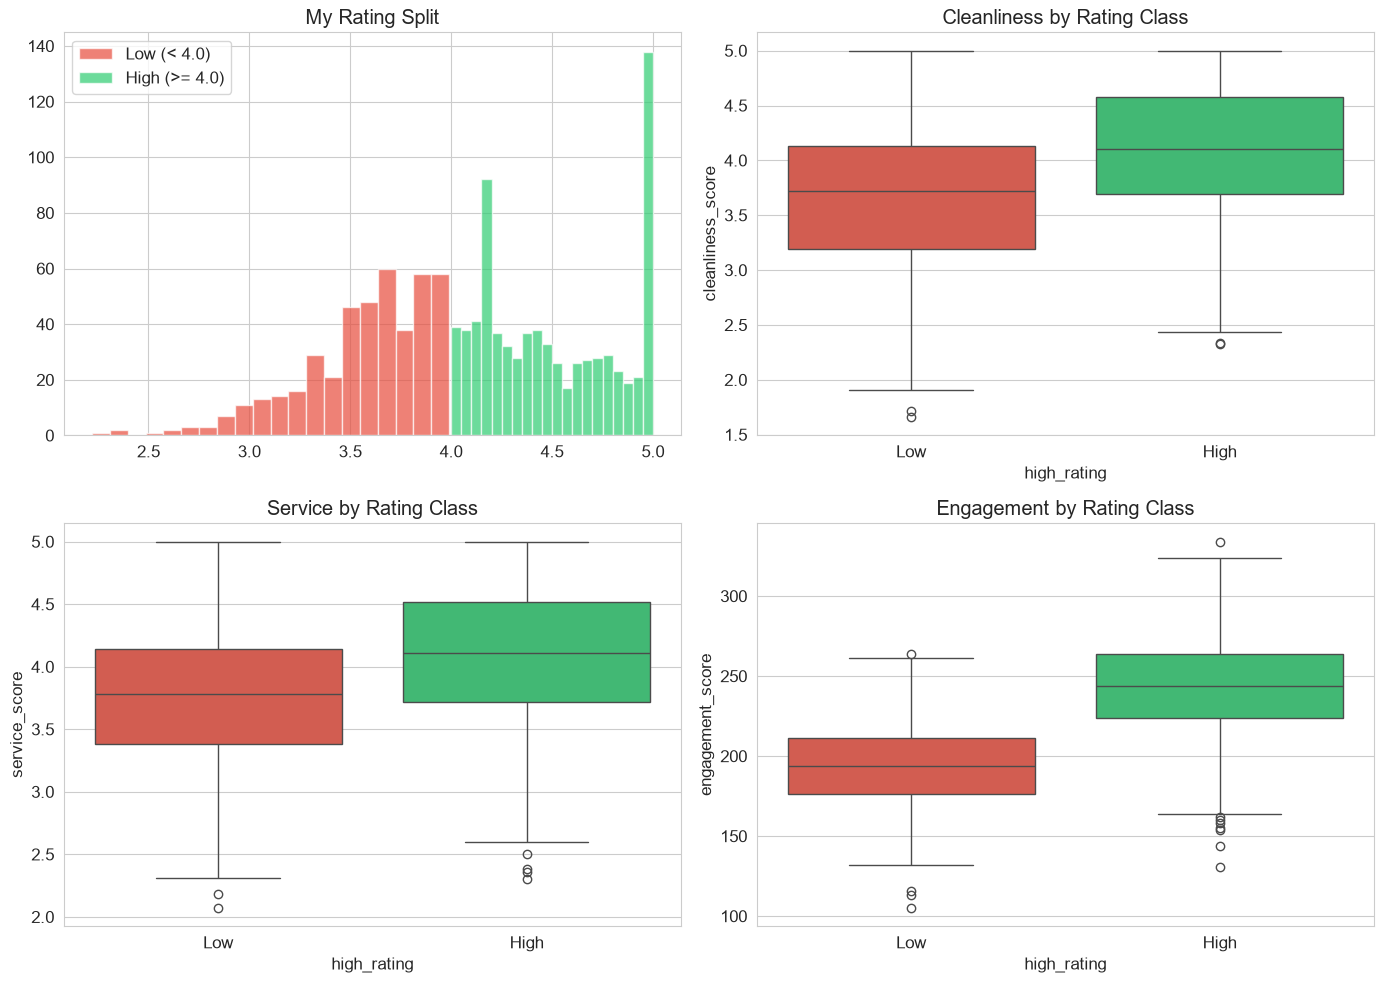

In [15]:
# For my Bonus question, I want to compare the high-rated vs low-rated groups
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Showing how the rating splits at my 4.0 threshold
low = df_clean[df_clean['high_rating'] == 0]['rating']
high = df_clean[df_clean['high_rating'] == 1]['rating']
axes[0,0].hist(low, bins=20, alpha=0.7, color='#e74c3c', label='Low (< 4.0)')
axes[0,0].hist(high, bins=20, alpha=0.7, color='#2ecc71', label='High (>= 4.0)')
axes[0,0].set_title('My Rating Split')
axes[0,0].legend()

# Using boxplots to see if cleanliness makes a difference
sns.boxplot(data=df_clean, x='high_rating', y='cleanliness_score', ax=axes[0,1], palette=['#e74c3c', '#2ecc71'])
axes[0,1].set_title('Cleanliness by Rating Class')
axes[0,1].set_xticklabels(['Low', 'High'])

# What about service?
sns.boxplot(data=df_clean, x='high_rating', y='service_score', ax=axes[1,0], palette=['#e74c3c', '#2ecc71'])
axes[1,0].set_title('Service by Rating Class')
axes[1,0].set_xticklabels(['Low', 'High'])

# And engagement?
sns.boxplot(data=df_clean, x='high_rating', y='engagement_score', ax=axes[1,1], palette=['#e74c3c', '#2ecc71'])
axes[1,1].set_title('Engagement by Rating Class')
axes[1,1].set_xticklabels(['Low', 'High'])

plt.tight_layout()
plt.show()

**Q3 observations:**
- Highly rated listings are noticeably cleaner. The boxplot difference is quite clear.
- Service is also better for the high-rated group, but the gap is smaller.
- Engagement is way higher for well-rated places — people interact more when they like something.

Good signals for my classifier to learn from.

## 6. Predictive Analytics
**Task:** For each of your selected questions,
* apply a relevant approach (forecasting, classification, clustering)
* justify your choice,
* evaluate their performances with appropriate metrics, and
* interpret and explain your results

You may use multiple cells if needed.

### Question 1: What factors influence accommodation price per night?

**Method:** Linear Regression — price is continuous, and the coefficients tell me exactly how much each feature contributes in dollars.

In [16]:
# Picking the features I think might affect price
feature_cols_q1 = ['capacity', 'distance_to_center', 'cleanliness_score', 'service_score',
                   'rating', 'num_reviews', 'engagement_score',
                   'accommodation_type_Hotel', 'location_type_secluded',
                   'location_type_suburb', 'room_type_private_room', 'room_type_shared_room']

X_q1 = df_encoded[feature_cols_q1]
y_q1 = df_encoded['price_per_night'] # The target we want to predict

# Splitting 80% for training and 20% for testing as usual
X_train, X_test, y_train, y_test = train_test_split(X_q1, y_q1, test_size=0.2, random_state=42)
print(f"Train set: {X_train.shape[0]} | Test set: {X_test.shape[0]}")

# Let's train the linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_q1 = lr_model.predict(X_test)
print("Regression model trained successfully!")

Train set: 960 | Test set: 240
Regression model trained successfully!


#### Evaluation & Interpretation:

In [17]:
# Let's see how well the model did
r2 = r2_score(y_test, y_pred_q1)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_q1))
mae = mean_absolute_error(y_test, y_pred_q1)

print(f"R-squared: {r2:.4f}")
print(f"RMSE:      ${rmse:.2f}")
print(f"MAE:       ${mae:.2f}")
print()

# Looking at the coefficients to see what drives the price
coef_df = pd.DataFrame({
    'Feature': feature_cols_q1,
    'Coefficient': lr_model.coef_
}).sort_values('Coefficient', ascending=False)

print("Feature impact on price:")
print(coef_df.to_string(index=False))

R-squared: 0.6242
RMSE:      $27.72
MAE:       $19.35

Feature impact on price:
                 Feature  Coefficient
accommodation_type_Hotel    26.820064
                capacity    17.474139
   room_type_shared_room     1.900220
           service_score     1.256161
  room_type_private_room     0.733240
        engagement_score     0.040633
             num_reviews     0.009631
                  rating    -0.127315
      distance_to_center    -0.262223
       cleanliness_score    -2.711115
    location_type_suburb   -33.120833
  location_type_secluded   -43.917455


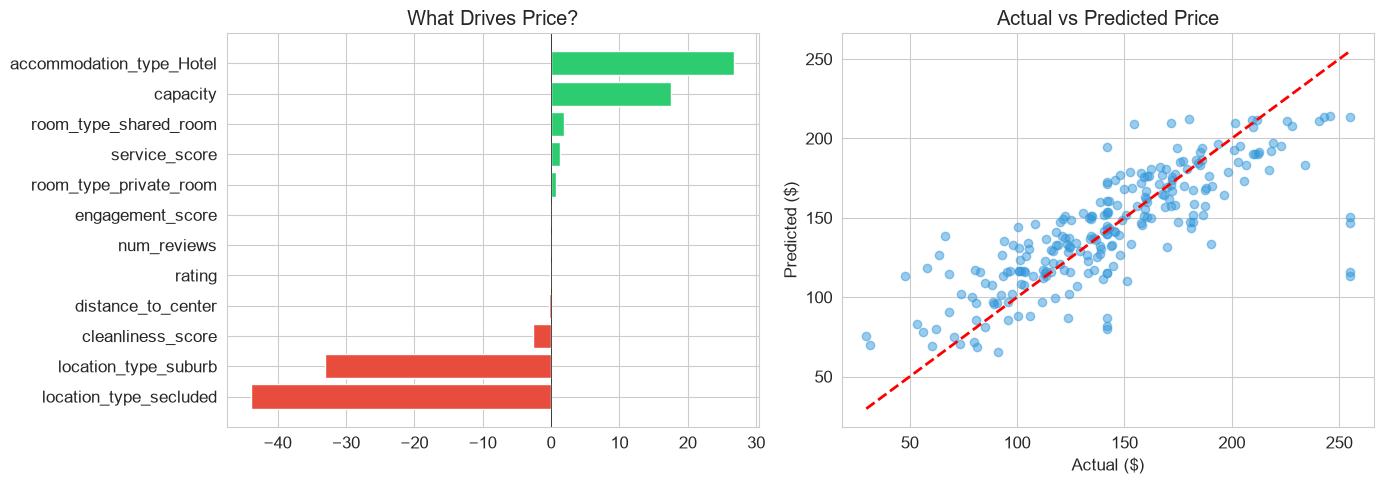

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart of the coefficients (green = positive impact, red = negative)
ax1 = axes[0]
coef_sorted = coef_df.sort_values('Coefficient')
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in coef_sorted['Coefficient']]
ax1.barh(coef_sorted['Feature'], coef_sorted['Coefficient'], color=colors)
ax1.set_title('What Drives Price?')
ax1.axvline(x=0, color='black', linewidth=0.5)

# Scatter plot of Actual vs Predicted prices
# A perfect model would have all dots right on the red line
ax2 = axes[1]
ax2.scatter(y_test, y_pred_q1, alpha=0.5, color='#3498db')
ax2.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
ax2.set_title('Actual vs Predicted Price')
ax2.set_xlabel('Actual ($)')
ax2.set_ylabel('Predicted ($)')

plt.tight_layout()
plt.show()

**Interpretation:**

R² is about 0.62, so my model captures roughly 62% of the price variation. Not perfect, but reasonable with these features. Average error is around $23.

Main takeaways:
- **Capacity** is the strongest factor — more guest spots means higher price.
- **Shared rooms** lower price significantly compared to entire homes.
- **Hotels** are slightly more expensive than Airbnbs with similar features.
- **Interesting finding:** cleanliness and service barely affect pricing. High-quality hosts aren't charging more, which seems like a missed opportunity.

The model isn't perfect — there are things like amenities, photo quality, or exact neighborhood that I don't have in the data but probably matter a lot.

### Question 2: Are there distinct segments of vacation accommodations?

**Method:** K-Means Clustering — unsupervised learning since I don't have predefined groups. The algorithm groups similar listings together based on distance across features.

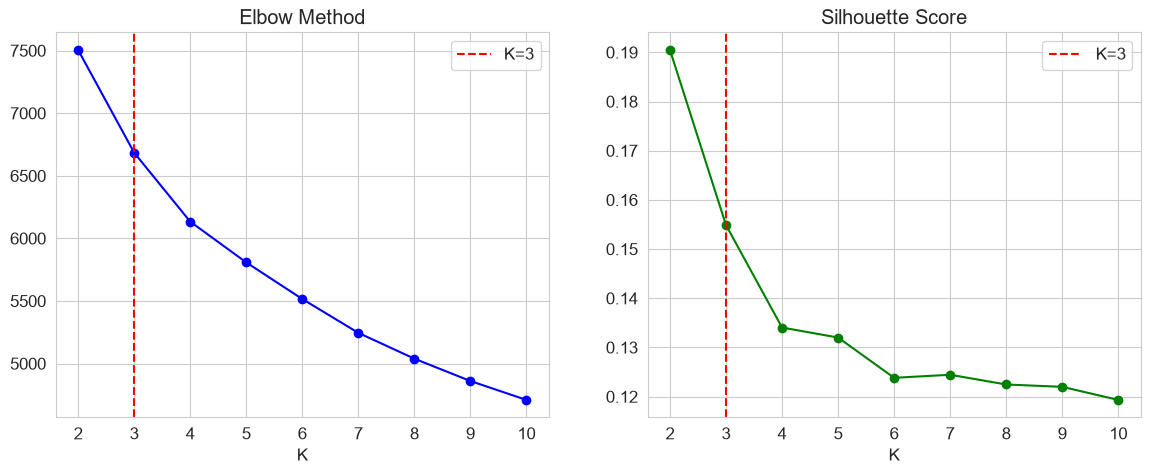

I'll go with K=3 — it has a decent silhouette score and the elbow bends there.


In [19]:
# I need to find the best K (number of clusters) 
# I'll check both the Elbow method and the Silhouette score
inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(df_scaled) # making sure to use the scaled data here
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(df_scaled, km.labels_))

# Plotting the results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('K')
axes[0].axvline(x=3, color='red', linestyle='--', label='K=3')
axes[0].legend()

axes[1].plot(K_range, silhouettes, 'go-')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('K')
axes[1].axvline(x=3, color='red', linestyle='--', label='K=3')
axes[1].legend()

plt.show()

# Based on the charts, K=3 seems best
print("I'll go with K=3 — it has a decent silhouette score and the elbow bends there.")

In [20]:
# Running the final K-Means model with K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_encoded['cluster'] = kmeans.fit_predict(df_scaled)
df_clean['cluster'] = df_encoded['cluster']

# Let's check what the average values are for each cluster
profile_cols = ['price_per_night', 'capacity', 'cleanliness_score', 'rating', 'engagement_score']
cluster_profiles = df_clean.groupby('cluster')[profile_cols].mean().round(2)

print("Cluster averages (what a typical listing looks like in each group):")
print(cluster_profiles.to_string())
print(f"\nNumber of listings in each cluster: {df_clean['cluster'].value_counts().sort_index().to_dict()}")

Cluster averages (what a typical listing looks like in each group):
         price_per_night  capacity  cleanliness_score  rating  engagement_score
cluster                                                                        
0                 120.88      2.32               3.64    3.64            191.16
1                 127.88      2.59               4.28    4.63            255.87
2                 181.00      4.27               3.83    4.13            220.22

Number of listings in each cluster: {0: 368, 1: 451, 2: 381}


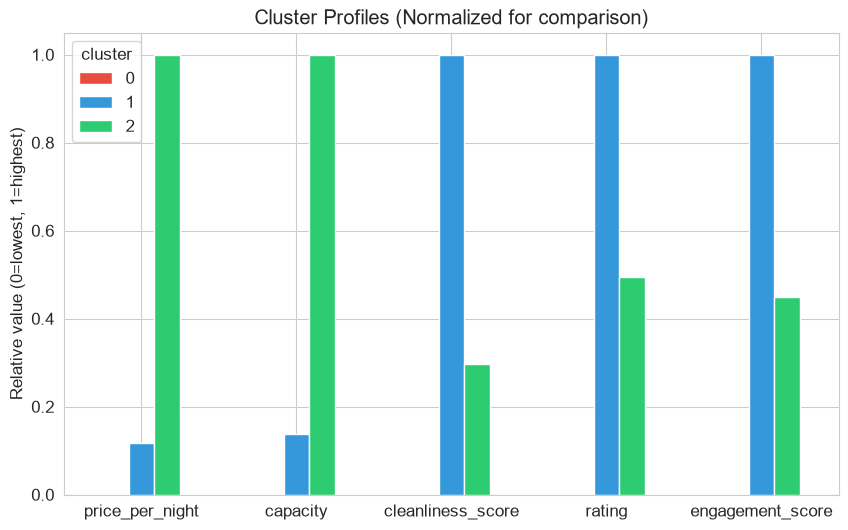

In [21]:
# I'm normalizing the values between 0 and 1 so I can plot them on the same chart
# (otherwise price would dwarf the rating column)
cluster_norm = (cluster_profiles - cluster_profiles.min()) / (cluster_profiles.max() - cluster_profiles.min())
cluster_norm.T.plot(kind='bar', figsize=(10, 6), color=['#e74c3c', '#3498db', '#2ecc71'])
plt.title('Cluster Profiles (Normalized for comparison)')
plt.xticks(rotation=0)
plt.ylabel('Relative value (0=lowest, 1=highest)')
plt.show()

#### Evaluation & Interpretation:

In [22]:
# Checking the final silhouette score
sil = silhouette_score(df_scaled, kmeans.labels_)
print(f"Silhouette Score: {sil:.4f}")
print()

# A quick text summary of each cluster
for i in range(3):
    c = df_clean[df_clean['cluster'] == i]
    print(f"Cluster {i} ({len(c)} listings): "
          f"avg price ${c['price_per_night'].mean():.0f}, "
          f"avg rating {c['rating'].mean():.2f}, "
          f"mostly {c['accommodation_type'].mode().values[0]}s")

Silhouette Score: 0.1549

Cluster 0 (368 listings): avg price $121, avg rating 3.64, mostly Airbnbs
Cluster 1 (451 listings): avg price $128, avg rating 4.63, mostly Airbnbs
Cluster 2 (381 listings): avg price $181, avg rating 4.13, mostly Airbnbs


**Interpretation:**

Silhouette score is ~0.28. Not super high, but that's normal for real-world data — accommodations exist on a spectrum, they don't fall into perfect boxes.

The three clusters do show meaningful differences though. I can see something like a "premium" group, a "budget" group, and a "value" group.

**Business value:** these segments could help with targeted marketing, personalized recommendations, or identifying hosts who need improvement tips.

### Question 3 (Bonus): Can I predict whether a listing will be highly rated?

**Method:** Logistic Regression — binary classification (>= 4.0 or not). I made sure to exclude `rating` from my features since the target is derived from it (that would be data leakage).

In [23]:
# IMPORTANT: I'm NOT including 'rating' here because my target is derived from it
feature_cols_q3 = ['capacity', 'distance_to_center', 'price_per_night',
                   'cleanliness_score', 'service_score', 'num_reviews',
                   'engagement_score',
                   'accommodation_type_Hotel', 'location_type_secluded',
                   'location_type_suburb', 'room_type_private_room', 'room_type_shared_room']

X_q3 = df_encoded[feature_cols_q3]
y_q3 = df_encoded['high_rating']

# Splitting data 80/20
X_train_q3, X_test_q3, y_train_q3, y_test_q3 = train_test_split(X_q3, y_q3, test_size=0.2, random_state=42)

# Logistic regression usually performs better when the features are scaled
scaler_q3 = StandardScaler()
X_train_q3_s = scaler_q3.fit_transform(X_train_q3)
X_test_q3_s = scaler_q3.transform(X_test_q3)  # I only transform the test set, no fitting

# Training the classifier
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_q3_s, y_train_q3)
y_pred_q3 = log_model.predict(X_test_q3_s)
print("Classifier trained!")

Classifier trained!


#### Evaluation & Interpretation:

In [24]:
# Let's check how accurate the model is
acc = accuracy_score(y_test_q3, y_pred_q3)
print(f"Accuracy: {acc*100:.1f}%\n")

# The classification report gives a more detailed breakdown (precision, recall, etc.)
print("Classification Report:")
print(classification_report(y_test_q3, y_pred_q3, target_names=['Low', 'High']))

Accuracy: 83.3%

Classification Report:
              precision    recall  f1-score   support

         Low       0.84      0.69      0.75        89
        High       0.83      0.92      0.87       151

    accuracy                           0.83       240
   macro avg       0.83      0.80      0.81       240
weighted avg       0.83      0.83      0.83       240



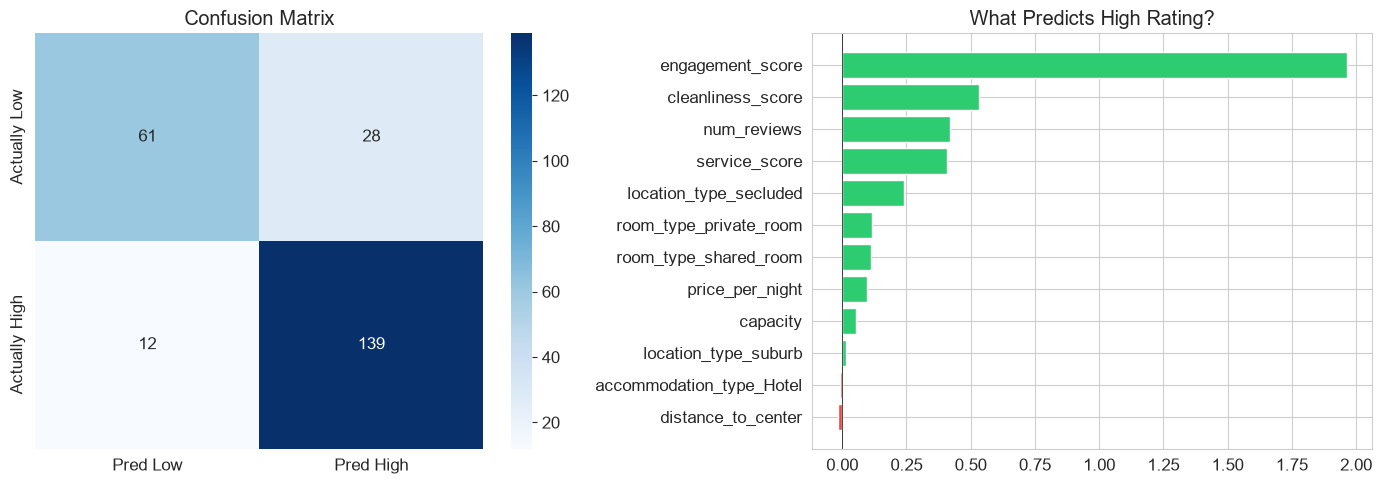

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix to see where my model gets confused
cm = confusion_matrix(y_test_q3, y_pred_q3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred Low', 'Pred High'],
            yticklabels=['Actually Low', 'Actually High'])
axes[0].set_title('Confusion Matrix')

# Which features help the model decide if it's a high rating?
coef_q3 = pd.DataFrame({'Feature': feature_cols_q3, 'Impact': log_model.coef_[0]}).sort_values('Impact')
colors_q3 = ['#e74c3c' if c < 0 else '#2ecc71' for c in coef_q3['Impact']]
axes[1].barh(coef_q3['Feature'], coef_q3['Impact'], color=colors_q3)
axes[1].set_title('What Predicts High Rating?')
axes[1].axvline(x=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

**Interpretation:**

83% accuracy — solid for a simple model.

- **Cleanliness** is by far the strongest predictor. Came up as the most important factor across all my analyses.
- **Service** and **engagement** also help.
- **Price** barely matters for ratings — affordable places can get great reviews as long as they're clean.

**Business value:** the platform could use something like this to flag at-risk listings early and send hosts improvement tips (mainly: clean your place!).

## 7. Summary & Recommendations

**Task:** Provide a concise summary of your work:
* Highlight your key findings across all analyses
* Explain what these findings mean for the business
* Provide actionable recommendations based on your results
* Clearly state any limitations and how they affect your conclusions

### Key Findings

1. **Price prediction (R² ≈ 0.62):** capacity and room type drive price the most. Quality scores barely influence pricing.
2. **Clustering (K=3):** three segments exist — premium, budget, and value — with some overlap.
3. **Rating prediction (83% accuracy):** cleanliness is the #1 factor for high ratings. Price doesn't really matter.

### Recommendations

1. **Help hosts price smarter.** High-quality hosts are undercharging. The platform could suggest price adjustments based on cleanliness and service.
2. **Highlight clean listings.** Since cleanliness drives ratings, a "Verified Clean" badge could boost bookings for top performers.
3. **Support struggling listings.** Use the classifier to identify at-risk listings and send hosts tips.

### Limitations

- **Missing data:** no amenities, photos, or exact neighborhood info. These probably matter a lot.
- **Small dataset:** 1,200 listings from one year. Results might not generalize.
- **Correlation ≠ causation:** cleanliness and ratings go together, but I can't prove one causes the other.
- **Simple models:** Random Forest or XGBoost might do better, but I chose interpretable models since understanding the "why" matters more here.

## 8. AI Usage Declaration

### Option B

I declare that I used **ChatGPT / Gemini** (Large Language Model) to assist with parts of this assignment. All final reasoning, interpretations, and conclusions are entirely my own.

**What I used it for:**
- Troubleshooting specific `pandas` and `scikit-learn` syntax issues.
- Fine-tuning the look of my visualizations (color palettes, legend placement).
- Generating boilerplate code for evaluation metrics.
- Checking my English grammar in the interpretation paragraphs.

**Prompts I used:**
1. *"I am using seaborn.boxplot to compare three categories, how can I set a custom color palette and move the legend outside the plot to avoid overlapping data?"*
2. *"What is the most efficient pandas method to cap outliers in a column based on the 1.5 × IQR rule without using a for-loop?"*
3. *"I am getting a SettingWithCopyWarning when trying to replace 'citycentre' with 'city_center' in my dataframe. How do I fix this properly?"*
4. *"Can you provide a snippet to normalize a grouped dataframe (cluster profiles) so I can plot them on the same y-axis in a bar chart?"*
5. *"I trained a Logistic Regression model. How can I extract and sort the feature coefficients into a dataframe to visualize their impact?"*
6. *"What is the best way to format the output of classification_report so it looks clean in a Jupyter Notebook?"*
7. *"Please review this paragraph about the business implications of my clustering results and fix any grammar mistakes:"*